# Homework 2
Q1

Q1 (a)

Write the two outputs of the network as $g(x) = (g_1(x), g_2(x)) \in \mathbb{R}^2$.

- **Mean:** the conditional mean can be any real number, so we use the identity link: $f_\mu(x) = g_1(x)$.
- **Standard deviation:** $f_\sigma(x)$ must be strictly positive, so we pass $g_2$ through a positive link. Two common choices are $f_\sigma(x) = \exp(g_2(x))$ or the softplus $f_\sigma(x) = \log(1 + e^{g_2(x)})$. I use softplus plus a small floor, $f_\sigma(x) = \text{softplus}(g_2(x)) + \varepsilon$ with $\varepsilon = 10^{-4}$: it grows only linearly for large $g_2$ (so gradients do not explode the way they can with $\exp$), and the floor stops $\sigma$ from collapsing to 0, where the log-likelihood would blow up.

Q1 (b)

If $Y_i \mid X_i \sim \mathcal{N}(f_\mu(X_i), f_\sigma(X_i)^2)$ independently, the negative log-likelihood of the data, averaged over $n$ observations, is

$$
\mathcal{L}(\theta) = \frac{1}{n}\sum_{i=1}^{n}\left[\frac{1}{2}\log(2\pi) + \log f_\sigma(X_i) + \frac{(Y_i - f_\mu(X_i))^2}{2 f_\sigma(X_i)^2}\right].
$$

This is the Gaussian negative log-likelihood (NLL). The squared error is weighted by $1/f_\sigma^2$, so the model can down-weight inputs where the noise is large, while the $\log f_\sigma$ term stops it from simply inflating $\sigma$ everywhere. If $f_\sigma$ were a constant, minimizing this would reduce to ordinary least squares.

Q1 (c)

In [1]:
import math, time, os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from scipy.stats import norm
from sklearn.model_selection import train_test_split, ParameterGrid
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import (mean_squared_error, brier_score_loss, log_loss,
                             accuracy_score, roc_auc_score, confusion_matrix)

SEED = 42
np.random.seed(SEED)
torch.manual_seed(SEED)
torch.set_num_threads(os.cpu_count())
print("torch", torch.__version__, "| threads", torch.get_num_threads())

torch 2.2.2 | threads 8


In [2]:
taxi = pd.read_parquet("taxi_trips.parquet")
print(taxi.shape)
display(taxi.head())
print(taxi["trip_duration"].describe().round(2))

y = taxi["trip_duration"].values.astype(np.float64)
X = taxi.drop(columns="trip_duration").values.astype(np.float32)
feature_names = taxi.drop(columns="trip_duration").columns.tolist()

# 70 / 15 / 15 split
X_tr, X_tmp, y_tr, y_tmp = train_test_split(X, y, test_size=0.30, random_state=SEED)
X_va, X_te, y_va, y_te = train_test_split(X_tmp, y_tmp, test_size=0.50, random_state=SEED)
print("train / val / test:", len(y_tr), len(y_va), len(y_te))

# standardize the target with TRAINING statistics only (features are already standardized)
y_mean, y_std = y_tr.mean(), y_tr.std()
Xtr_t, Xva_t, Xte_t = (torch.tensor(a) for a in (X_tr, X_va, X_te))
ytr_t = torch.tensor((y_tr - y_mean) / y_std, dtype=torch.float32)
yva_t = torch.tensor((y_va - y_mean) / y_std, dtype=torch.float32)

(523554, 8)


,pickup_longitude,pickup_latitude,dropoff_longitude,dropoff_latitude,trip_duration,min_of_day,day_of_week,day_of_year
187173,0.270744,1.425051,0.466831,0.776192,7.965142,-0.942057,-1.047619,1.180855
179655,0.085681,0.306079,-0.226274,0.124111,10.680277,0.778703,-1.047619,-0.311290
120048,-0.555533,-0.934806,-0.022489,-0.548561,5.716184,-1.183016,-1.047619,1.316504
62587,0.069718,0.035804,0.258900,0.317284,4.266709,-0.908008,0.481657,0.018144
212063,-0.234482,0.074616,0.115836,0.258310,11.629685,1.066806,-0.537860,0.521985


count    523554.00
mean         10.41
std           7.75
min           0.03
25%           4.75
50%           8.63
75%          13.93
max         227.94
Name: trip_duration, dtype: float64
train / val / test: 366487 78533 78534


In [3]:
EPS = 1e-4

class HeteroMLP(nn.Module):
    """MLP g: R^p -> R^2, with links mu = g1 and sigma = softplus(g2) + eps."""
    def __init__(self, d_in, hidden=64, n_layers=2):
        super().__init__()
        layers, width = [], d_in
        for _ in range(n_layers):
            layers += [nn.Linear(width, hidden), nn.ReLU()]
            width = hidden
        self.body = nn.Sequential(*layers)
        self.head = nn.Linear(width, 2)

    def forward(self, x):
        out = self.head(self.body(x))
        mu = out[:, 0]
        sigma = F.softplus(out[:, 1]) + EPS
        return mu, sigma

def gaussian_nll(mu, sigma, y):
    return (0.5 * math.log(2 * math.pi) + torch.log(sigma) + (y - mu) ** 2 / (2 * sigma ** 2)).mean()

def mse_loss(mu, sigma, y):           # used for the homoscedastic MLP baseline (ignores sigma)
    return ((y - mu) ** 2).mean()

# NumPy version, used to score every model (in minutes) on the test set
def gaussian_nll_np(y, mu, sigma):
    return np.mean(0.5 * np.log(2 * np.pi) + np.log(sigma) + (y - mu) ** 2 / (2 * sigma ** 2))

In [4]:
def train_model(hidden, n_layers, lr, loss_fn=gaussian_nll, batch_size=1024,
                max_epochs=40, patience=5, seed=SEED, verbose=False):
    """Adam + early stopping on the validation loss; returns the best-validation weights."""
    torch.manual_seed(seed)
    model = HeteroMLP(Xtr_t.shape[1], hidden, n_layers)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state, bad_epochs = float("inf"), None, 0
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(Xtr_t))
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            loss = loss_fn(*model(Xtr_t[idx]), ytr_t[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(*model(Xva_t), yva_t).item()
        if verbose:
            print(f"  epoch {epoch + 1:2d}  val loss {val_loss:.4f}", flush=True)
        if val_loss < best_val:
            best_val, bad_epochs = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    return model, best_val, epoch + 1

def predict_minutes(model, X_t):
    with torch.no_grad():
        mu, sigma = model(X_t)
    return mu.numpy() * y_std + y_mean, sigma.numpy() * y_std

**Baselines.** The MLP should beat each of these:
1. *Constant Gaussian*: predict the training mean and training standard deviation for every trip (no features at all).
2. *Linear regression + constant σ*: linear mean, σ = std of the training residuals.
3. *Gradient boosting + constant σ*: a strong non-linear model of the mean (`HistGradientBoostingRegressor`), σ = std of training residuals.
4. *Homoscedastic MLP*: the same network architecture trained with MSE (so only the mean is learned), σ = std of training residuals. This isolates the value of modelling σ(x).

In [5]:
baselines = {}

# 1. constant Gaussian
baselines["constant Gaussian"] = (np.full_like(y_te, y_tr.mean()), np.full_like(y_te, y_tr.std()))

# 2. linear regression + constant sigma
lin = LinearRegression().fit(X_tr, y_tr)
baselines["linear regression + const σ"] = (lin.predict(X_te), np.full_like(y_te, np.std(y_tr - lin.predict(X_tr))))

# 3. gradient boosting + constant sigma (early stopping on an internal 10% split of train)
t0 = time.time()
hgb = HistGradientBoostingRegressor(max_iter=500, learning_rate=0.1, max_leaf_nodes=63,
                                    early_stopping=True, random_state=SEED).fit(X_tr, y_tr)
baselines["gradient boosting + const σ"] = (hgb.predict(X_te), np.full_like(y_te, np.std(y_tr - hgb.predict(X_tr))))
print(f"HGB: {hgb.n_iter_} iterations, {time.time() - t0:.1f}s")

# 4. homoscedastic MLP (same architecture as the final model, trained with MSE)
t0 = time.time()
mse_mlp, _, n_ep = train_model(hidden=128, n_layers=3, lr=1e-3, loss_fn=mse_loss)
mu_tr_h, _ = predict_minutes(mse_mlp, Xtr_t)
mu_te_h, _ = predict_minutes(mse_mlp, Xte_t)
baselines["homoscedastic MLP (MSE) + const σ"] = (mu_te_h, np.full_like(y_te, np.std(y_tr - mu_tr_h)))
print(f"homoscedastic MLP: {n_ep} epochs, {time.time() - t0:.1f}s")

pd.DataFrame([{"model": k, "test MSE": mean_squared_error(y_te, mu), "test NLL": gaussian_nll_np(y_te, mu, s)}
              for k, (mu, s) in baselines.items()]).round(3)

HGB: 500 iterations, 30.5s
homoscedastic MLP: 40 epochs, 26.9s


,model,test MSE,test NLL
0,constant Gaussian,60.169,3.468
1,linear regression + const σ,56.919,3.440
2,gradient boosting + const σ,14.496,2.770
3,homoscedastic MLP (MSE) + const σ,14.214,2.750


**Hyper-parameter search for the heteroscedastic MLP.** Each configuration is trained with Adam on the Gaussian NLL, with early stopping on the validation NLL (patience 5). The best configuration is chosen by validation NLL only; the test set is not touched.

In [6]:
grid = {"hidden": [64, 128, 256], "n_layers": [2, 3], "lr": [1e-3]}
rows, best = [], (None, float("inf"), None)
t_all = time.time()
for params in ParameterGrid(grid):
    t0 = time.time()
    model, val_nll, n_ep = train_model(**params)
    rows.append({**params, "val NLL (std. units)": val_nll, "epochs": n_ep, "seconds": round(time.time() - t0)})
    print(params, f"val NLL {val_nll:.4f}  epochs {n_ep}  ({time.time() - t0:.0f}s)", flush=True)
    if val_nll < best[1]:
        best = (model, val_nll, params)
model, best_val_nll, best_params = best
print(f"total {time.time() - t_all:.0f}s | best: {best_params}, val NLL {best_val_nll:.4f}")
pd.DataFrame(rows).sort_values("val NLL (std. units)").reset_index(drop=True)

{'hidden': 64, 'lr': 0.001, 'n_layers': 2} val NLL 0.5985  epochs 31  (11s)
{'hidden': 64, 'lr': 0.001, 'n_layers': 3} val NLL 0.5511  epochs 40  (17s)
{'hidden': 128, 'lr': 0.001, 'n_layers': 2} val NLL 0.5915  epochs 25  (11s)
{'hidden': 128, 'lr': 0.001, 'n_layers': 3} val NLL 0.5431  epochs 23  (14s)
{'hidden': 256, 'lr': 0.001, 'n_layers': 2} val NLL 0.5630  epochs 33  (27s)
{'hidden': 256, 'lr': 0.001, 'n_layers': 3} val NLL 0.5352  epochs 29  (36s)
total 116s | best: {'hidden': 256, 'lr': 0.001, 'n_layers': 3}, val NLL 0.5352


,hidden,lr,n_layers,val NLL (std. units),epochs,seconds
0,256,0.001,3,0.535197,29,36
1,128,0.001,3,0.543115,23,14
2,64,0.001,3,0.551085,40,17
3,256,0.001,2,0.563034,33,27
4,128,0.001,2,0.591502,25,11
5,64,0.001,2,0.598483,31,11


In [7]:
mu_te, sigma_te = predict_minutes(model, Xte_t)

rows = [{"model": k, "test MSE": mean_squared_error(y_te, mu), "test NLL": gaussian_nll_np(y_te, mu, s),
         "95% interval coverage": np.mean(np.abs(y_te - mu) <= 1.96 * s)}
        for k, (mu, s) in baselines.items()]
rows.append({"model": "heteroscedastic MLP (NLL)", "test MSE": mean_squared_error(y_te, mu_te),
             "test NLL": gaussian_nll_np(y_te, mu_te, sigma_te),
             "95% interval coverage": np.mean(np.abs(y_te - mu_te) <= 1.96 * sigma_te)})
q1_results = pd.DataFrame(rows)
display(q1_results.round(3))

print("predicted sigma (minutes) on test:", pd.Series(sigma_te).describe().round(2).to_dict())

,model,test MSE,test NLL,95% interval coverage
0,constant Gaussian,60.169,3.468,0.959
1,linear regression + const σ,56.919,3.440,0.958
2,gradient boosting + const σ,14.496,2.770,0.946
3,homoscedastic MLP (MSE) + const σ,14.214,2.750,0.953
4,heteroscedastic MLP (NLL),14.839,2.758,0.955


predicted sigma (minutes) on test: {'count': 78534.0, 'mean': 3.19, 'std': 1.75, 'min': 0.82, '25%': 2.17, '50%': 2.87, '75%': 3.75, 'max': 63.64}


In [8]:
# The mean NLL is sensitive to a handful of extreme trips (the Gaussian tail is very light).
# Compare per-trip NLL contributions on validation and test: median, worst trips, and the mean after dropping the 20 worst.
def per_trip_nll(y, mu, s):
    return 0.5 * np.log(2 * np.pi) + np.log(s) + (y - mu) ** 2 / (2 * s ** 2)

mu_va, sigma_va = predict_minutes(model, Xva_t)
mu_va_h, _ = predict_minutes(mse_mlp, Xva_t)
s_h = baselines["homoscedastic MLP (MSE) + const σ"][1][0]
rows = []
for name, (mv, sv, mt, st) in {
        "homoscedastic MLP (MSE) + const σ": (mu_va_h, np.full_like(y_va, s_h), mu_te_h, np.full_like(y_te, s_h)),
        "heteroscedastic MLP (NLL)": (mu_va, sigma_va, mu_te, sigma_te)}.items():
    for split, yy, mu, s in [("val", y_va, mv, sv), ("test", y_te, mt, st)]:
        per = np.sort(per_trip_nll(yy, mu, s))[::-1]
        rows.append({"model": name, "split": split, "mean NLL": per.mean(), "median NLL": np.median(per),
                     "worst trip NLL": per[0], "share of mean from worst 10": per[:10].sum() / per.sum(),
                     "mean NLL without worst 20 trips": per[20:].mean()})
display(pd.DataFrame(rows).round(4))

worst = np.argsort(per_trip_nll(y_te, mu_te, sigma_te))[::-1][:5]
pd.DataFrame({"actual (min)": y_te[worst], "pred mean": mu_te[worst], "pred σ": sigma_te[worst],
              "z = (y − μ)/σ": (y_te[worst] - mu_te[worst]) / sigma_te[worst]}).round(2)

,model,split,mean NLL,median NLL,worst trip NLL,share of mean from worst 10,mean NLL without worst 20 trips
0,homoscedastic MLP (MSE) + const σ,val,2.7110,2.2991,645.1352,0.0122,2.6653
1,homoscedastic MLP (MSE) + const σ,test,2.7496,2.2979,1139.7587,0.0231,2.6692
2,heteroscedastic MLP (NLL),val,2.5836,2.2401,1318.2190,0.0232,2.5123
3,heteroscedastic MLP (NLL),test,2.7580,2.2405,6966.8966,0.0739,2.5304


,actual (min),pred mean,pred σ,z = (y − μ)/σ
0,173.34,3.66,1.44,118.03
1,136.68,2.04,2.15,62.77
2,147.58,5.57,2.57,55.33
3,130.57,6.26,2.44,51.05
4,147.65,10.35,2.71,50.73


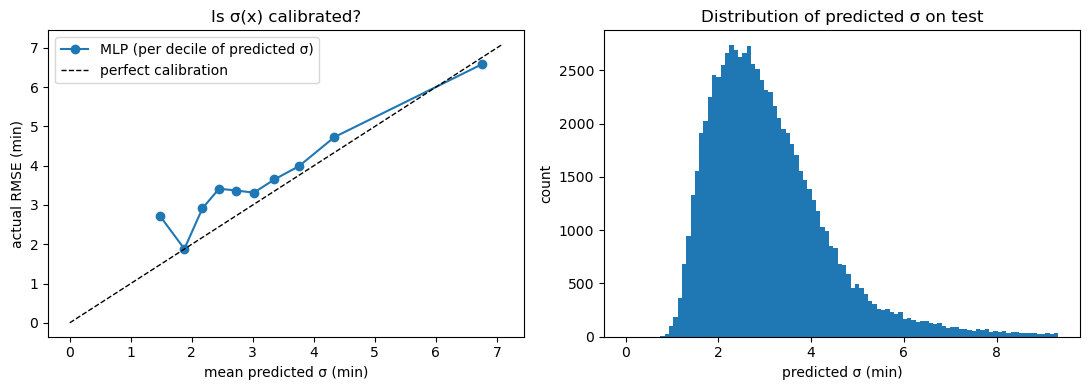

,mean_pred_sigma,rmse
"(0.82, 1.717]",1.48,2.72
"(1.717, 2.031]",1.88,1.88
"(2.031, 2.31]",2.17,2.91
"(2.31, 2.585]",2.45,3.42
"(2.585, 2.865]",2.72,3.37
"(2.865, 3.176]",3.02,3.32
"(3.176, 3.54]",3.35,3.65
"(3.54, 4.0]",3.76,3.99
"(4.0, 4.783]",4.34,4.73
"(4.783, 63.644]",6.76,6.58


In [9]:
# Does the predicted sigma track the actual error? Bin test trips by predicted sigma.
bins = pd.qcut(sigma_te, 10)
calib = pd.DataFrame({"pred sigma": sigma_te, "abs err": np.abs(y_te - mu_te), "sq err": (y_te - mu_te) ** 2}) \
          .groupby(bins, observed=True).agg(mean_pred_sigma=("pred sigma", "mean"), rmse=("sq err", lambda s: np.sqrt(s.mean())))
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(calib["mean_pred_sigma"], calib["rmse"], "o-", label="MLP (per decile of predicted σ)")
lim = [0, calib[["mean_pred_sigma", "rmse"]].values.max() * 1.05]
ax[0].plot(lim, lim, "k--", lw=1, label="perfect calibration")
ax[0].set_xlabel("mean predicted σ (min)"); ax[0].set_ylabel("actual RMSE (min)"); ax[0].legend()
ax[0].set_title("Is σ(x) calibrated?")
ax[1].hist(sigma_te, bins=100, range=(0, np.quantile(sigma_te, 0.99)))
ax[1].set_xlabel("predicted σ (min)"); ax[1].set_ylabel("count"); ax[1].set_title("Distribution of predicted σ on test")
plt.tight_layout(); plt.show()
calib.round(2)

I split the 523,554 trips 70/15/15 into train/validation/test (366,487 / 78,533 / 78,534) and standardized the target with training statistics. The heteroscedastic MLP was tuned on validation NLL over 6 configurations (width 64/128/256 × 2 or 3 hidden layers, Adam lr = 1e-3, early stopping with patience 5). The best was **3 hidden layers of 256 units**. Deeper networks were consistently better than 2-layer ones.

**Test results (minutes):**

| model | test MSE | test NLL |
|---|---|---|
| constant Gaussian | 60.17 | 3.468 |
| linear regression + const σ | 56.92 | 3.440 |
| gradient boosting + const σ | 14.50 | 2.770 |
| homoscedastic MLP (MSE) + const σ | 14.21 | 2.750 |
| **heteroscedastic MLP (NLL)** | 14.84 | 2.758 |

- The non-linear models are far better than the constant and linear baselines (MSE 14–15 vs 57–60). Linear regression barely beats the mean because trip duration depends on the *distance* between pickup and dropoff, which is not a linear function of the coordinates.
- On the mean alone, the heteroscedastic MLP is slightly worse than the MSE-trained MLP (14.84 vs 14.21). This is expected: the NLL down-weights noisy trips by $1/\sigma^2$, so it does not minimize squared error directly.
- **Modelling σ(x) does help.** On validation, the heteroscedastic MLP's NLL is 2.584 vs 2.711 for the homoscedastic one, and the median per-trip NLL is lower on both splits (2.24 vs 2.30). Its predicted σ ranges from about 0.8 to 64 minutes (median 2.9), and the decile plot shows that trips with larger predicted σ really do have larger errors (RMSE grows from about 2 to 6.6 minutes). The 95% intervals cover 95.5% of test trips.
- **But the mean test NLL is fragile.** On test, the heteroscedastic model's mean NLL (2.758) is about tied with the homoscedastic one (2.750). This is driven by a handful of trips. One trip took 173 minutes when the model predicted 3.7 ± 1.4 (z ≈ 118), and that single trip contributes about 0.09 to the mean NLL. These look like data errors or extreme events (e.g. a meter left running). With the 20 worst of 78,534 trips removed, the ranking is clear: 2.530 (heteroscedastic) vs 2.669 (homoscedastic). The Gaussian has very light tails, so one confident miss is punished enormously. A heavier-tailed likelihood (e.g. Student-t or log-normal) would be more robust here.

Q1 (d)

Under the model, $Y \mid X = x \sim \mathcal{N}(f_\mu(x), f_\sigma(x)^2)$, so

$$
P(Y < 45 \mid X = x) = \Phi\!\left(\frac{45 - f_\mu(x)}{f_\sigma(x)}\right),
$$

where $\Phi$ is the standard normal CDF. For each trip we plug in the network's predicted mean and standard deviation (converted back to minutes) and evaluate $\Phi$. Note that the heteroscedastic model matters here: two trips with the same predicted mean get different probabilities if their predicted noise levels differ.

In [10]:
THRESH = 45.0
p_less_45 = norm.cdf((THRESH - mu_te) / sigma_te)

pd.DataFrame({"predicted mean (min)": mu_te[:10], "predicted σ (min)": sigma_te[:10],
              "P(< 45 min)": p_less_45[:10], "actual duration (min)": y_te[:10]}).round(3)

,predicted mean (min),predicted σ (min),P(< 45 min),actual duration (min)
0,2.713,2.556,1.0,6.083
1,6.894,2.780,1.0,2.534
2,11.322,3.670,1.0,8.148
3,9.633,2.245,1.0,10.814
4,5.011,2.117,1.0,6.083
5,11.537,2.619,1.0,14.678
6,13.680,3.136,1.0,10.231
7,7.835,2.123,1.0,4.850
8,14.893,3.127,1.0,11.913
9,15.977,3.987,1.0,15.527


Q1 (e)

In [11]:
label = (y_te < THRESH).astype(int)        # 1 = trip under 45 minutes
print(f"fraction of test trips under 45 min: {label.mean():.4f}")

def prob_metrics(name, p):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    pred = (p > 0.5).astype(int)
    return {"model": name,
            "Brier score": brier_score_loss(label, p),
            "log-loss": log_loss(label, p, labels=[0, 1]),
            "accuracy (p > 0.5)": accuracy_score(label, pred),
            "ROC AUC": roc_auc_score(label, p) if np.unique(p).size > 1 else 0.5}

rows = [prob_metrics("constant: train fraction under 45", np.full(len(y_te), (y_tr < THRESH).mean()))]
for k, (mu, s) in baselines.items():
    if k != "constant Gaussian":
        rows.append(prob_metrics(k, norm.cdf((THRESH - mu) / s)))
rows.append(prob_metrics("heteroscedastic MLP (NLL)", p_less_45))
q1e = pd.DataFrame(rows)
display(q1e.round(4))

pred = (p_less_45 > 0.5).astype(int)
print("confusion matrix for the MLP (rows = actual [>=45, <45], cols = predicted):")
print(confusion_matrix(label, pred, labels=[0, 1]))
long = label == 0
print(f"long trips (>= 45 min) correctly flagged: {(pred[long] == 0).sum()} / {long.sum()}")

fraction of test trips under 45 min: 0.9955


,model,Brier score,log-loss,accuracy (p > 0.5),ROC AUC
0,constant: train fraction under 45,0.0044,0.0286,0.9955,0.5000
1,linear regression + const σ,0.0045,0.0459,0.9955,0.8478
2,gradient boosting + const σ,0.0026,0.0295,0.9971,0.9414
3,homoscedastic MLP (MSE) + const σ,0.0026,0.0293,0.9972,0.9358
4,heteroscedastic MLP (NLL),0.0028,0.0222,0.9966,0.9405


confusion matrix for the MLP (rows = actual [>=45, <45], cols = predicted):
[[  163   187]
 [   77 78107]]
long trips (>= 45 min) correctly flagged: 163 / 350


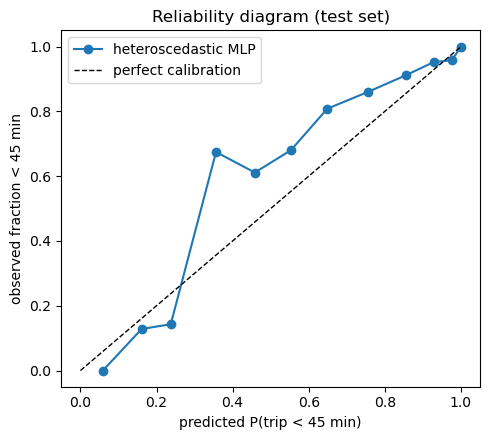

,mean_pred,observed,n
bin,,,
0,0.059,0.000,34
1,0.161,0.128,39
2,0.237,0.143,70
3,0.356,0.674,43
4,0.458,0.611,54
5,0.553,0.680,75
6,0.649,0.808,99
7,0.756,0.860,143
8,0.855,0.911,248


In [12]:
# reliability diagram: predicted P(< 45) vs observed frequency
edges = np.array([0, .1, .2, .3, .4, .5, .6, .7, .8, .9, .95, .99, 1.0])
b = np.clip(np.digitize(p_less_45, edges[1:-1]), 0, len(edges) - 2)
rel = pd.DataFrame({"p": p_less_45, "y": label, "bin": b}).groupby("bin").agg(
    mean_pred=("p", "mean"), observed=("y", "mean"), n=("y", "size"))
plt.figure(figsize=(5, 4.5))
plt.plot(rel["mean_pred"], rel["observed"], "o-", label="heteroscedastic MLP")
plt.plot([0, 1], [0, 1], "k--", lw=1, label="perfect calibration")
plt.xlabel("predicted P(trip < 45 min)"); plt.ylabel("observed fraction < 45 min")
plt.title("Reliability diagram (test set)"); plt.legend(); plt.tight_layout(); plt.show()
rel.round(3)

Only 0.45% of test trips (350 of 78,534) take 45 minutes or more, so this is a very imbalanced problem. The right comparison is against the constant predictor that always outputs the training fraction (0.9955).

| model | Brier | log-loss | accuracy (p > 0.5) | AUC |
|---|---|---|---|---|
| constant (train fraction) | 0.0044 | 0.0286 | 0.9955 | 0.500 |
| linear + const σ | 0.0045 | 0.0459 | 0.9955 | 0.848 |
| gradient boosting + const σ | 0.0026 | 0.0295 | 0.9971 | 0.941 |
| homoscedastic MLP + const σ | 0.0026 | 0.0293 | 0.9972 | 0.936 |
| **heteroscedastic MLP** | 0.0028 | **0.0222** | 0.9966 | 0.941 |

- **Proper scoring rules.** The heteroscedastic MLP has by far the best log-loss (0.0222, a 22% improvement over the constant predictor). Its Brier score (0.0028) is 36% better than the constant predictor and close to the best (0.0026). The constant-σ models put essentially all of their probability on "< 45" and get log-loss no better than the constant predictor (0.029). They cannot express that a particular trip is unusually uncertain, so they are badly wrong on the long trips. Modelling σ(x) is what makes the probabilities useful in the tail, which is exactly what log-loss rewards.
- **Accuracy.** Thresholding at 0.5 gives 99.66% accuracy vs 99.55% for always predicting "under 45". This is a small gain, because accuracy is dominated by the majority class. The model correctly flags 163 of the 350 long trips (47%), with 77 false alarms.
- **Calibration.** The reliability diagram tracks the diagonal reasonably well. In the middle range (predicted 0.3–0.9), the model is somewhat *under*-confident that trips finish in under 45 minutes (e.g. predicted 0.36, observed 0.67). This is consistent with duration being right-skewed: a symmetric Gaussian puts too much mass above the mean for these long, uncertain trips.

Q2

Q2 (a)

In [13]:
from sklearn.metrics import mean_poisson_deviance, mean_absolute_error

retail = pd.read_csv("retail.csv")
columns = ["StockCode", "CustomerID"]
retail["CustomerID"] = retail["CustomerID"].astype(int)
for c in columns:
    retail[c] = retail[c].astype(str).astype("category")
print(retail.shape)
display(retail.head())

# 1. cardinality
print("unique values:", retail[columns].nunique().to_dict())

# 2. rows per category
for c in columns:
    counts = retail[c].value_counts()
    print(f"{c}: median rows per category {counts.median():.0f}, max {counts.max()}, "
          f"categories with < 10 rows: {(counts < 10).mean():.1%}")

# 3. size of a dense one-hot encoding
n_cols = retail[columns].nunique().sum()
print(f"dense one-hot: {len(retail):,} rows x {n_cols:,} columns = {len(retail) * n_cols / 1e9:.2f} billion entries "
      f"(~{len(retail) * n_cols * 8 / 1e9:.0f} GB as float64)")

# 4. the target is very heavy-tailed
print(retail["Quantity"].describe().round(2).to_dict())
print("quantiles:", retail["Quantity"].quantile([.5, .9, .99, .999]).to_dict())
print("orders > 1000:", (retail["Quantity"] > 1000).sum(), "| largest:", sorted(retail["Quantity"])[-5:])

(397924, 3)


,Quantity,StockCode,CustomerID
0,6,85123A,17850
1,6,71053,17850
2,8,84406B,17850
3,6,84029G,17850
4,6,84029E,17850


unique values: {'StockCode': 3665, 'CustomerID': 4339}
StockCode: median rows per category 49, max 2035, categories with < 10 rows: 21.4%
CustomerID: median rows per category 41, max 7847, categories with < 10 rows: 13.4%
dense one-hot: 397,924 rows x 8,004 columns = 3.18 billion entries (~25 GB as float64)
{'count': 397924.0, 'mean': 13.02, 'std': 180.42, 'min': 1.0, '25%': 2.0, '50%': 6.0, '75%': 12.0, 'max': 80995.0}
quantiles: {0.5: 6.0, 0.9: 24.0, 0.99: 120.0, 0.999: 504.0}
orders > 1000: 106 | largest: [4300, 4800, 12540, 74215, 80995]


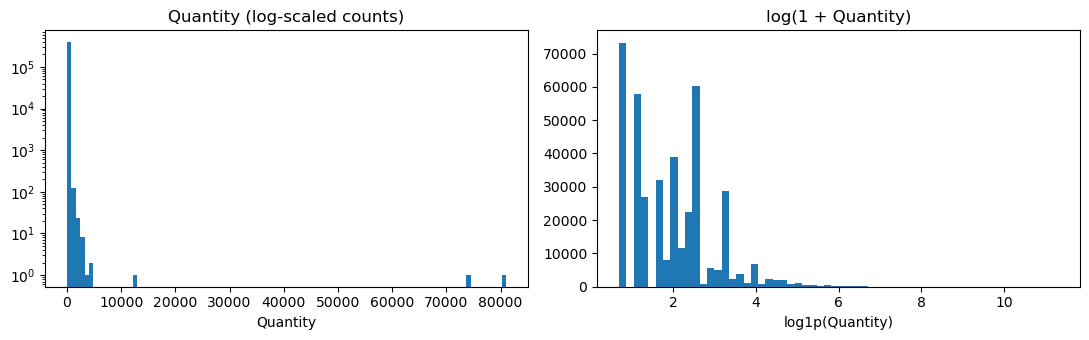

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].hist(retail["Quantity"], bins=100, log=True); ax[0].set_title("Quantity (log-scaled counts)"); ax[0].set_xlabel("Quantity")
ax[1].hist(np.log1p(retail["Quantity"]), bins=60); ax[1].set_title("log(1 + Quantity)"); ax[1].set_xlabel("log1p(Quantity)")
plt.tight_layout(); plt.show()

In [15]:
# Remove the handful of extreme bulk orders (> 1000 units, incl. the 80,995 / 74,215 data-entry errors);
# they are <0.03% of rows but would dominate any squared-error or Poisson loss.
retail = retail[retail["Quantity"] <= 1000].reset_index(drop=True)

# 70 / 15 / 15 split
r_tr, r_tmp = train_test_split(retail, test_size=0.30, random_state=SEED)
r_va, r_te = train_test_split(r_tmp, test_size=0.50, random_state=SEED)
q_tr, q_va, q_te = (d["Quantity"].values.astype(np.float64) for d in (r_tr, r_va, r_te))
print("train / val / test:", len(q_tr), len(q_va), len(q_te))
for c in columns:
    print(c, "- test rows whose category is unseen in train:", f"{(~r_te[c].isin(set(r_tr[c]))).mean():.2%}")

def report(name, pred):
    return {"model": name,
            "Poisson deviance": mean_poisson_deviance(q_te, pred),
            "MAE": mean_absolute_error(q_te, pred),
            "RMSE on log1p scale": np.sqrt(np.mean((np.log1p(q_te) - np.log1p(pred)) ** 2))}

q2_results = {}
def add_result(name, pred):
    q2_results[name] = report(name, pred)
    return pd.DataFrame(q2_results.values()).round(3)

add_result("mean baseline", np.full(len(q_te), q_tr.mean()))

train / val / test: 278472 59673 59673
StockCode - test rows whose category is unseen in train: 0.08%
CustomerID - test rows whose category is unseen in train: 0.01%


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198


**StockCode has 3,665 unique values and CustomerID has 4,339.** Both are high-cardinality: a dense one-hot encoding would have 8,004 columns and about 3.2 billion entries (≈ 25 GB as float64). That is not feasible in memory (a sparse matrix would fit, but it still gives each category its own independent coefficient). Many categories are also rare: 21% of products and 13% of customers have fewer than 10 rows, so their one-hot coefficients would be poorly estimated. This suggests a compact encoding that shares statistical strength across categories, such as target encoding (one number per category) or learned embeddings (a low-dimensional vector per category).

Quantity is very heavy-tailed: the median is 6, the 99th percentile is 120, and the maximum is 80,995. I dropped the 106 orders above 1,000 units (0.03% of rows, including the two obvious 74,215 / 80,995 data errors). With a squared-error or Poisson loss these few rows would dominate training and evaluation. Then I split 70/15/15 into train/validation/test (278,472 / 59,673 / 59,673). Almost every test category is seen in training (only 0.08% of test rows have an unseen StockCode). The mean baseline has a test Poisson deviance of 24.53.

Q2 (b)

`category_encoders` is not installed in this environment, so I use scikit-learn's `TargetEncoder`, which does the same thing (per-category mean of the training target, shrunk toward the global mean for rare categories) and additionally *cross-fits* on the training set: each training row is encoded using means computed from the other folds, so a row never sees its own label. Validation/test rows use means from the full training set, and unseen categories get the global mean.

**Loss.** Quantity is a positive count with a heavy right tail, so I model it with a Poisson loss and a log link (predictions are always positive, and errors on large orders are penalized in proportion to their size rather than quadratically). Models are evaluated with the mean Poisson deviance (the proper scoring rule matching this loss); MAE and RMSE on the log1p scale are reported for reference.

In [16]:
from sklearn.preprocessing import TargetEncoder
from sklearn.linear_model import PoissonRegressor
from sklearn.model_selection import KFold

te = TargetEncoder(target_type="continuous", cv=KFold(5, shuffle=True, random_state=SEED))
TE_tr = te.fit_transform(r_tr[columns].astype(str), q_tr)    # cross-fitted on train
TE_va = te.transform(r_va[columns].astype(str))
TE_te = te.transform(r_te[columns].astype(str))
print("categories:", [len(c) for c in te.categories_], "| global mean:", round(float(te.target_mean_), 3))
display(pd.DataFrame(TE_tr[:5], columns=[c + "_TE" for c in columns]).assign(Quantity=q_tr[:5]).round(2))

# Model 1: Poisson GLM on log(target-encoded means)  ->  log E[Q] = b0 + b1 log(TE_stock) + b2 log(TE_cust)
glm = PoissonRegressor(alpha=1e-4, max_iter=1000).fit(np.log(TE_tr), q_tr)
print("GLM coefficients:", glm.coef_.round(3), "intercept:", round(glm.intercept_, 3))
print("GLM val Poisson deviance:", round(mean_poisson_deviance(q_va, glm.predict(np.log(TE_va))), 3))
add_result("target encoding + Poisson GLM", glm.predict(np.log(TE_te)))

categories: [3600, 4315] | global mean: 12.157


,StockCode_TE,CustomerID_TE,Quantity
0,7.76,16.78,2.0
1,15.51,25.92,12.0
2,14.50,26.17,6.0
3,2.66,15.66,1.0
4,6.60,5.27,1.0


GLM coefficients: [0.758 0.977] intercept: -1.785
GLM val Poisson deviance: 7.885


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198
1,target encoding + Poisson GLM,8.180,7.253,0.661


In [17]:
# Model 2: gradient boosting with a Poisson loss on the target-encoded features
# (early stopping on our validation set by choosing the number of trees there)
t0 = time.time()
hgb_te = HistGradientBoostingRegressor(loss="poisson", max_iter=400, learning_rate=0.05, max_leaf_nodes=31,
                                       early_stopping=False, random_state=SEED).fit(TE_tr, q_tr)
val_curve = [mean_poisson_deviance(q_va, p) for p in hgb_te.staged_predict(TE_va)]
best_iter = int(np.argmin(val_curve)) + 1
hgb_te = HistGradientBoostingRegressor(loss="poisson", max_iter=best_iter, learning_rate=0.05, max_leaf_nodes=31,
                                       early_stopping=False, random_state=SEED).fit(TE_tr, q_tr)
print(f"best #trees on validation: {best_iter} (val deviance {min(val_curve):.3f}), {time.time() - t0:.0f}s")
add_result("target encoding + Poisson gradient boosting", hgb_te.predict(TE_te))

best #trees on validation: 93 (val deviance 7.805), 11s


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198
1,target encoding + Poisson GLM,8.180,7.253,0.661
2,target encoding + Poisson gradient boosting,8.040,7.161,0.659


Each training row is replaced by the (cross-fitted, smoothed) mean Quantity of its StockCode and of its CustomerID. Since the target is a count with a log link, I fit two models on the encoded features:

- **Poisson GLM on log(TE values):** $\log \mathbb{E}[Q] = -1.79 + 0.76 \log \text{TE}_\text{stock} + 0.98 \log \text{TE}_\text{cust}$. This is a multiplicative "product effect × customer effect" model. Test Poisson deviance **8.18** (vs 24.53 for the mean baseline), MAE 7.25.
- **Poisson gradient boosting on the TE values** (number of trees chosen on the validation set: 93). This allows a non-linear interaction between the two encoded means. Test Poisson deviance **8.04**, MAE 7.16.

Target encoding captures most of the signal: deviance drops by about 67% relative to the mean. Gradient boosting only improves slightly on the GLM. With just two scalar inputs, there is little structure left for a flexible model to exploit.

Q2 (c)

In [18]:
# integer ids for the embedding layer; id 0 is reserved for categories unseen in training
maps = {c: {cat: i + 1 for i, cat in enumerate(r_tr[c].unique())} for c in columns}

def to_idx(df, c):
    return torch.tensor(df[c].astype(str).map(maps[c]).fillna(0).astype(np.int64).values)

S_tr, S_va, S_te = (to_idx(d, "StockCode") for d in (r_tr, r_va, r_te))
C_tr, C_va, C_te = (to_idx(d, "CustomerID") for d in (r_tr, r_va, r_te))
qt_tr, qt_va = torch.tensor(q_tr, dtype=torch.float32), torch.tensor(q_va, dtype=torch.float32)
n_stock, n_cust = len(maps["StockCode"]), len(maps["CustomerID"])
print("n_stock", n_stock, "n_cust", n_cust)

class EmbNet(nn.Module):
    def __init__(self, n_stock, n_cust, emb_dim=16, n_extra=0, hidden=64):
        super().__init__()
        # padding_idx=0: unseen categories map to a fixed all-zero vector instead of an untrained random one
        self.emb_s = nn.Embedding(n_stock + 1, emb_dim, padding_idx=0)
        self.emb_c = nn.Embedding(n_cust + 1, emb_dim, padding_idx=0)
        self.mlp = nn.Sequential(nn.Linear(2 * emb_dim + n_extra, hidden), nn.ReLU(), nn.Linear(hidden, 1))

    def forward(self, s, c, extra=None):
        z = [self.emb_s(s), self.emb_c(c)]
        if extra is not None:
            z.append(extra)
        return self.mlp(torch.cat(z, dim=1)).squeeze(1)      # log of the predicted Quantity

poisson_loss = nn.PoissonNLLLoss(log_input=True)

def train_net(model, tr_inputs, y_train, va_inputs, y_val, lr=1e-3, batch_size=1024,
              max_epochs=60, patience=3, seed=SEED):
    torch.manual_seed(seed)
    optimizer = torch.optim.Adam(model.parameters(), lr=lr)
    best_val, best_state, bad_epochs = float("inf"), None, 0
    t0 = time.time()
    for epoch in range(max_epochs):
        model.train()
        perm = torch.randperm(len(y_train))
        for i in range(0, len(perm), batch_size):
            idx = perm[i:i + batch_size]
            loss = poisson_loss(model(*[t[idx] for t in tr_inputs]), y_train[idx])
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
        model.eval()
        with torch.no_grad():
            val_loss = poisson_loss(model(*va_inputs), y_val).item()
        if val_loss < best_val:
            best_val, bad_epochs = val_loss, 0
            best_state = {k: v.clone() for k, v in model.state_dict().items()}
        else:
            bad_epochs += 1
            if bad_epochs >= patience:
                break
    model.load_state_dict(best_state)
    model.eval()
    print(f"stopped after {epoch + 1} epochs ({time.time() - t0:.0f}s), best val Poisson NLL {best_val:.4f}")
    return model

def predict_q(model, inputs):
    model.eval()
    with torch.no_grad():
        return torch.exp(model(*inputs)).numpy().astype(np.float64)

n_stock 3600 n_cust 4315


In [19]:
# embedding dimension: rule of thumb ~ cardinality^(1/4) ≈ 8; quick check of a few sizes on VALIDATION
emb_rows = {}
for d in [4, 16, 32]:
    torch.manual_seed(SEED)
    m = train_net(EmbNet(n_stock, n_cust, emb_dim=d), (S_tr, C_tr), qt_tr, (S_va, C_va), qt_va)
    emb_rows[d] = (m, mean_poisson_deviance(q_va, predict_q(m, (S_va, C_va))))
    print(f"emb_dim={d}: val Poisson deviance {emb_rows[d][1]:.3f}", flush=True)
best_dim = min(emb_rows, key=lambda d: emb_rows[d][1])
emb_model = emb_rows[best_dim][0]
print("chosen emb_dim:", best_dim)
add_result(f"embeddings NN (dim {best_dim})", predict_q(emb_model, (S_te, C_te)))

stopped after 45 epochs (11s), best val Poisson NLL -26.5782
emb_dim=4: val Poisson deviance 6.695
stopped after 30 epochs (10s), best val Poisson NLL -26.5784
emb_dim=16: val Poisson deviance 6.694
stopped after 29 epochs (11s), best val Poisson NLL -26.6010
emb_dim=32: val Poisson deviance 6.649
chosen emb_dim: 32


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198
1,target encoding + Poisson GLM,8.180,7.253,0.661
2,target encoding + Poisson gradient boosting,8.040,7.161,0.659
3,embeddings NN (dim 32),6.919,6.557,0.611


Each feature gets its own embedding table (one learned vector per StockCode and per CustomerID; unseen categories map to a fixed zero vector). The two vectors are concatenated and fed through a one-hidden-layer MLP (64 ReLU units) that outputs $\log \mathbb{E}[Q]$. The network is trained with the Poisson NLL, Adam, and early stopping on the validation loss. For the embedding dimension, the rule of thumb (cardinality$^{1/4}$ ≈ 8) suggests a small value. I compared 4, 16 and 32 on the **validation** set: 6.695, 6.694 and 6.649. All three are close, and 32 was selected.

The embedding model reaches a test Poisson deviance of **6.92** (MAE 6.56). That is clearly better than both target-encoding models (8.18 / 8.04), a 14% reduction in deviance relative to the best TE model.

Q2 (d)

In [20]:
# target-encoded features on log scale, standardized with training statistics
logTE_tr, logTE_va, logTE_te = np.log(TE_tr), np.log(TE_va), np.log(TE_te)
m_, s_ = logTE_tr.mean(0), logTE_tr.std(0)
to_feat = lambda a: torch.tensor((a - m_) / s_, dtype=torch.float32)
T_tr, T_va, T_te = to_feat(logTE_tr), to_feat(logTE_va), to_feat(logTE_te)

torch.manual_seed(SEED)
both_model = train_net(EmbNet(n_stock, n_cust, emb_dim=best_dim, n_extra=2),
                       (S_tr, C_tr, T_tr), qt_tr, (S_va, C_va, T_va), qt_va)
add_result("embeddings + target encoding NN", predict_q(both_model, (S_te, C_te, T_te)))

stopped after 19 epochs (7s), best val Poisson NLL -26.4774


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198
1,target encoding + Poisson GLM,8.180,7.253,0.661
2,target encoding + Poisson gradient boosting,8.040,7.161,0.659
3,embeddings NN (dim 32),6.919,6.557,0.611
4,embeddings + target encoding NN,7.118,6.652,0.622


In [21]:
# Is the gap between (c) and (d) real or one lucky run? Retrain both over 3 seeds.
seed_rows = []
for seed in range(3):
    torch.manual_seed(seed)
    m_emb = train_net(EmbNet(n_stock, n_cust, emb_dim=best_dim), (S_tr, C_tr), qt_tr, (S_va, C_va), qt_va, seed=seed)
    torch.manual_seed(seed)
    m_both = train_net(EmbNet(n_stock, n_cust, emb_dim=best_dim, n_extra=2),
                       (S_tr, C_tr, T_tr), qt_tr, (S_va, C_va, T_va), qt_va, seed=seed)
    seed_rows.append({"seed": seed,
                      "embeddings": mean_poisson_deviance(q_te, predict_q(m_emb, (S_te, C_te))),
                      "embeddings + TE": mean_poisson_deviance(q_te, predict_q(m_both, (S_te, C_te, T_te)))})
seed_df = pd.DataFrame(seed_rows)
seed_df["difference"] = seed_df["embeddings + TE"] - seed_df["embeddings"]
display(seed_df.round(3))
display(seed_df[["embeddings", "embeddings + TE", "difference"]].agg(["mean", "std"]).round(3))

stopped after 30 epochs (11s), best val Poisson NLL -26.5875
stopped after 13 epochs (5s), best val Poisson NLL -26.3538
stopped after 21 epochs (10s), best val Poisson NLL -26.5920
stopped after 20 epochs (11s), best val Poisson NLL -26.4338
stopped after 22 epochs (11s), best val Poisson NLL -26.5519
stopped after 13 epochs (7s), best val Poisson NLL -26.3174


,seed,embeddings,embeddings + TE,difference
0,0,7.001,7.353,0.352
1,1,7.030,7.143,0.113
2,2,7.075,7.404,0.329


,embeddings,embeddings + TE,difference
mean,7.035,7.300,0.264
std,0.037,0.138,0.132


Adding the two (log, standardized) target-encoded features as extra inputs to the embedding network gives a test deviance of **7.12**. That is better than target encoding alone (8.04–8.18) but **worse than embeddings alone (6.92)**. Retraining both networks with 3 seeds confirms this is not a fluke: 7.04 ± 0.04 for embeddings vs 7.30 ± 0.14 for embeddings + TE, and the combined model is worse on every seed.

The combined model also stops much earlier (13–21 epochs vs 21–30). The TE features are an easy, ready-made summary of each category, so the network leans on them early, and the validation loss starts rising before the embeddings have learned finer per-category structure. The TE values carry little information that the embeddings cannot learn themselves, because both are estimated from the same training labels. Note also that the training-set TE values are cross-fitted while the validation/test values use full-data means, so the extra inputs are slightly noisier in training than at test time. Together, these mean the combination adds redundancy and a shortcut rather than new information.

Q2 (e)

In [22]:
# Where do the models differ? Break the test deviance down by how often the StockCode appears in training.
train_counts = r_tr["StockCode"].astype(str).value_counts()
cnt = r_te["StockCode"].astype(str).map(train_counts).fillna(0).values
bucket = pd.cut(cnt, [-1, 0, 9, 99, 499, np.inf], labels=["unseen", "1-9", "10-99", "100-499", "500+"])

preds = {"TE + Poisson GLM": glm.predict(np.log(TE_te)),
         "TE + Poisson GBM": hgb_te.predict(TE_te),
         "embeddings NN": predict_q(emb_model, (S_te, C_te)),
         "embeddings + TE NN": predict_q(both_model, (S_te, C_te, T_te))}
rows = []
for b in bucket.categories:
    mask = np.asarray(bucket == b)
    if mask.sum() == 0:
        continue
    row = {"StockCode train count": b, "test rows": int(mask.sum())}
    for k, p in preds.items():
        row[k] = mean_poisson_deviance(q_te[mask], p[mask])
    rows.append(row)
pd.DataFrame(rows).round(3)

,StockCode train count,test rows,TE + Poisson GLM,TE + Poisson GBM,embeddings NN,embeddings + TE NN
0,unseen,46,6.298,6.759,3.526,3.728
1,1-9,866,14.554,11.325,8.993,12.987
2,10-99,16687,7.745,7.803,6.949,7.087
3,100-499,34168,8.270,8.111,6.842,7.028
4,500+,7906,8.019,7.884,6.979,6.951


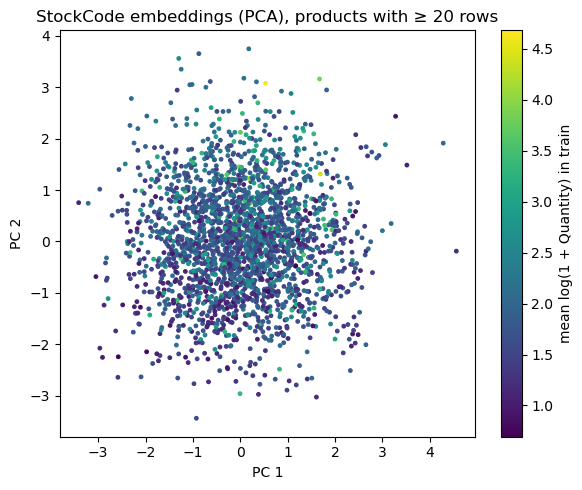

corr(PC1, mean log quantity): 0.059
5-fold R^2 of predicting a product's mean log-quantity linearly from its embedding: 0.347


,model,Poisson deviance,MAE,RMSE on log1p scale
0,mean baseline,24.534,11.802,1.198
1,target encoding + Poisson GLM,8.180,7.253,0.661
2,target encoding + Poisson gradient boosting,8.040,7.161,0.659
3,embeddings NN (dim 32),6.919,6.557,0.611
4,embeddings + target encoding NN,7.118,6.652,0.622


In [23]:
# What has the StockCode embedding learned? Project the learned vectors to 2-D with PCA and
# colour each product by its (training-set) mean log quantity.
from sklearn.decomposition import PCA

W = emb_model.emb_s.weight.detach().numpy()[1:]                       # drop the padding row
inv = {i: cat for cat, i in maps["StockCode"].items()}
cats = [inv[i + 1] for i in range(n_stock)]
stats = r_tr.assign(logq=np.log1p(q_tr), sc=r_tr["StockCode"].astype(str)).groupby("sc")["logq"].agg(["mean", "size"])
mean_logq = stats.loc[cats, "mean"].values
n_rows = stats.loc[cats, "size"].values

pcs = PCA(2).fit_transform(W)
keep = n_rows >= 20                                                    # products with enough data to trust their mean
plt.figure(figsize=(6, 5))
sc = plt.scatter(pcs[keep, 0], pcs[keep, 1], c=mean_logq[keep], s=6, cmap="viridis")
plt.colorbar(sc, label="mean log(1 + Quantity) in train")
plt.xlabel("PC 1"); plt.ylabel("PC 2"); plt.title("StockCode embeddings (PCA), products with ≥ 20 rows")
plt.tight_layout(); plt.show()
print("corr(PC1, mean log quantity):", round(np.corrcoef(pcs[keep, 0], mean_logq[keep])[0, 1], 3))

# a linear map from the 16-d embedding to the product's mean log-quantity: how much of the TE signal is inside?
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import cross_val_score
r2 = cross_val_score(RidgeCV(), W[keep], mean_logq[keep], cv=5, scoring="r2").mean()
print(f"5-fold R^2 of predicting a product's mean log-quantity linearly from its embedding: {r2:.3f}")

display(pd.DataFrame(q2_results.values()).round(3))

**What the embedding layer does.** An embedding is a learned lookup table: it is equivalent to multiplying a one-hot vector by a weight matrix, so each category gets a dense vector trained end-to-end to reduce the loss. Target encoding compresses each category into *one number* (its average quantity), chosen before seeing the model and identical for every combination. An embedding can store *several* directions of variation (bulk vs. retail products, wholesale vs. retail customers, product type, …). The MLP on top can then learn **interactions**: e.g. a wholesale customer buys certain items in bulk but other items singly. Neither the GLM nor the boosting model on two scalar means can represent that. Because similar categories get similar vectors, information is also shared between them.

**Evidence on the test set.**
- The embedding NN wins in every frequency bucket of StockCode. The gap is largest for rare products (1–9 training rows: 8.99 vs 11.3–14.6 for TE), where the target-encoded mean is noisy and heavily shrunk toward the global mean. The embedding model can still place the product sensibly using the customer's vector and the interaction. For frequent products (100+ rows) the embedding model is still about 15% better (6.84–6.98 vs 7.88–8.27). Even when a product's mean is known precisely, *who* is buying it matters, and only the interaction-capable model uses that.
- The embedding contains the target-encoding signal, but not only that. A linear map from the 32-d StockCode embedding predicts a product's mean log-quantity with cross-validated R² ≈ 0.35. The first principal component is almost uncorrelated with it (r = 0.06). So the dominant directions in embedding space are not just "average quantity", and the rest of the vector encodes other structure that the MLP exploits. This also explains (d): giving the network the TE values is largely redundant.

**Overall (test Poisson deviance):** mean 24.53 → TE + GLM 8.18 → TE + GBM 8.04 → embeddings + TE 7.12 → **embeddings 6.92**.

Q3

Q3 (a)

train (600, 2) val (200, 2) test (200, 2) | test labels: None
y train: mean 1.533, var 2.463, range [-1.30, 5.64]


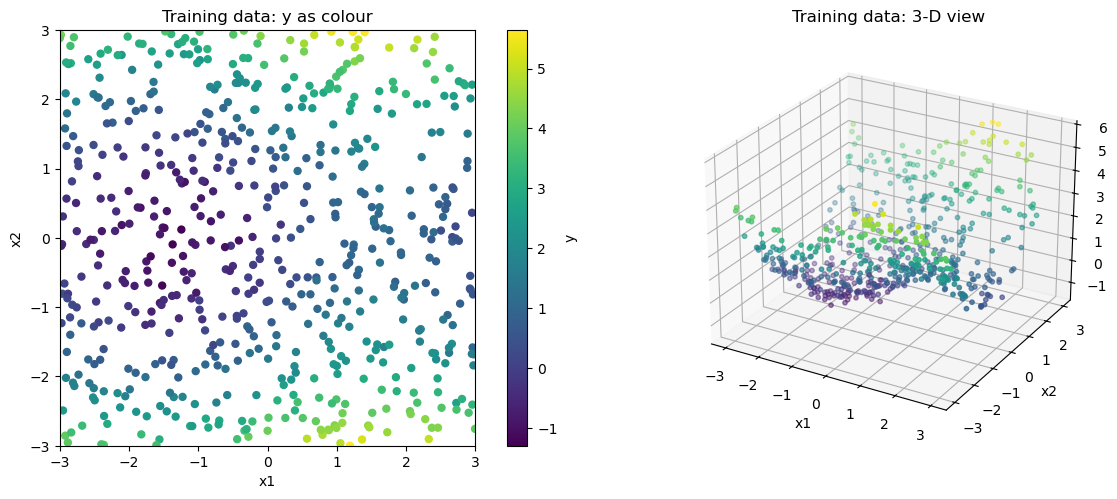

In [24]:
import sys
sys.path.insert(0, ".")
from dataloader import HW2Dataset
from plotting import plot_surface_2d

ds = HW2Dataset.from_csv("train.csv", "val.csv", "test.csv")
X3_tr, y3_tr = ds.train.X, ds.train.y
X3_va, y3_va = ds.val.X, ds.val.y
X3_te = ds.test.X
print("train", X3_tr.shape, "val", X3_va.shape, "test", X3_te.shape, "| test labels:", ds.test.y)
print(f"y train: mean {y3_tr.mean():.3f}, var {y3_tr.var():.3f}, range [{y3_tr.min():.2f}, {y3_tr.max():.2f}]")

fig = plt.figure(figsize=(13, 5))
ax = fig.add_subplot(1, 2, 1)
s = ax.scatter(X3_tr[:, 0], X3_tr[:, 1], c=y3_tr, cmap="viridis", s=25)
fig.colorbar(s, ax=ax, label="y")
ax.set_xlabel("x1"); ax.set_ylabel("x2"); ax.set_title("Training data: y as colour")
ax.set_xlim(-3, 3); ax.set_ylim(-3, 3); ax.set_aspect("equal")
ax3 = fig.add_subplot(1, 2, 2, projection="3d")
ax3.scatter(X3_tr[:, 0], X3_tr[:, 1], y3_tr, c=y3_tr, cmap="viridis", s=10)
ax3.set_xlabel("x1"); ax3.set_ylabel("x2"); ax3.set_zlabel("y"); ax3.set_title("Training data: 3-D view")
ax3.view_init(elev=25, azim=-60)
plt.tight_layout(); plt.show()

The response is a smooth function of $(x_1, x_2)$ with no sharp edges. There is a low basin near $(x_1, x_2) \approx (-1.5, 0)$ (y ≈ −1), y increases with $|x_2|$ (a bowl along $x_2$, highest near $x_2 = \pm 3$, y ≈ 5), and there is a saddle around $(1.5, 0)$. Along $x_1$ the function rises and falls roughly like a sinusoid (similar to $\sin(x_1) + c\,x_2^2$). The surface has low-frequency structure, so we expect a smooth kernel / small network to fit well. The training points look reasonably uniform over $[-3, 3]^2$, with some visible noise.

Q3 (b)

**Implementation.** Following the assignment, $w_j \sim \mathcal{N}_d(0, I_d/\sigma^2)$ and $b_j \sim U[0, 2\pi]$ for $j = 1,\dots,h$, and $z_i = (\sin(w_j^\top x_i + b_j), \cos(w_j^\top x_i + b_j))_{j}$, with $D = 2h$. I scale the features by $1/\sqrt{h}$ (so $z_i^\top z_k$ approximates the Gaussian kernel $\exp(-\|x_i - x_k\|^2 / 2\sigma^2)$ and $\lambda$ has the same meaning for every $D$) and add an unpenalized intercept. Ridge regression minimizes $\frac{1}{n}\|y - Z\beta\|^2 + \lambda\|\beta\|^2$, solved in closed form as $\beta = (Z^\top Z + n\lambda I)^{-1} Z^\top y$.

**Sweep.** I vary the kernel scale $\sigma$ (the bandwidth: small $\sigma$ means high-frequency random features and a wiggly fit, large $\sigma$ means low-frequency features and a smooth fit), keeping $D = 1000$ and $\lambda = 10^{-4}$ fixed. To reduce the noise from the random draw of features, each $\sigma$ is averaged over 5 random feature seeds.

In [25]:
class RandomKitchenSinks:
    """Random Kitchen Sinks featurization (sin & cos) + ridge regression."""
    def __init__(self, D: int = 1000, sigma: float = 1.0, ridge_lambda: float = 1e-4, seed: int = 0):
        assert D % 2 == 0, "D = 2h must be even (sin + cos per random direction)"
        self.D, self.h, self.sigma, self.ridge_lambda, self.seed = D, D // 2, sigma, ridge_lambda, seed
        self.W = self.b = self.coef_ = None

    def _features(self, X: np.ndarray) -> np.ndarray:
        proj = X @ self.W + self.b                                     # (n, h)
        phi = np.hstack([np.sin(proj), np.cos(proj)]) / np.sqrt(self.h)
        return np.hstack([np.ones((len(X), 1)), phi])                  # (n, D + 1), first column = intercept

    def fit(self, X: np.ndarray, y: np.ndarray):
        rng = np.random.default_rng(self.seed)
        self.W = rng.normal(0.0, 1.0 / self.sigma, size=(X.shape[1], self.h))   # w_j ~ N(0, I / sigma^2)
        self.b = rng.uniform(0.0, 2 * np.pi, size=self.h)                        # b_j ~ U[0, 2pi]
        phi = self._features(X)
        n = len(X)
        reg = n * self.ridge_lambda * np.eye(phi.shape[1])
        reg[0, 0] = 0.0                                                # do not penalize the intercept
        self.coef_ = np.linalg.solve(phi.T @ phi + reg, phi.T @ y)
        return self

    def predict(self, X: np.ndarray) -> np.ndarray:
        return self._features(X) @ self.coef_

mse = lambda y, p: float(np.mean((np.ravel(y) - np.ravel(p)) ** 2))

def sweep_rks_sigma(sigmas, X_train, y_train, X_val, y_val, D=1000, ridge_lambda=1e-4, seeds=range(5)):
    rows = []
    for s in sigmas:
        tr, va = [], []
        for seed in seeds:
            m = RandomKitchenSinks(D=D, sigma=s, ridge_lambda=ridge_lambda, seed=seed).fit(X_train, y_train)
            tr.append(mse(y_train, m.predict(X_train))); va.append(mse(y_val, m.predict(X_val)))
        rows.append({"sigma": s, "train MSE": np.mean(tr), "val MSE": np.mean(va), "val MSE sd": np.std(va)})
    return pd.DataFrame(rows)

sigmas = np.logspace(-1.5, 1, 21)
rks_sweep = sweep_rks_sigma(sigmas, X3_tr, y3_tr, X3_va, y3_va)
best_sigma = rks_sweep.loc[rks_sweep["val MSE"].idxmin(), "sigma"]
print(f"best sigma = {best_sigma:.4f}  (val MSE {rks_sweep['val MSE'].min():.4f})")
rks_sweep.round(4)

best sigma = 2.3714  (val MSE 0.0368)


,sigma,train MSE,val MSE,val MSE sd
0,0.0316,0.0536,3.8877,0.5490
1,0.0422,0.0528,3.7330,0.5893
2,0.0562,0.0565,3.1626,0.6721
3,0.0750,0.0463,2.7044,0.8642
4,0.1000,0.0330,1.5104,0.7554
5,0.1334,0.0153,0.4096,0.2894
6,0.1778,0.0159,0.1782,0.0772
7,0.2371,0.0181,0.0746,0.0149
8,0.3162,0.0220,0.0534,0.0036
9,0.4217,0.0262,0.0469,0.0027


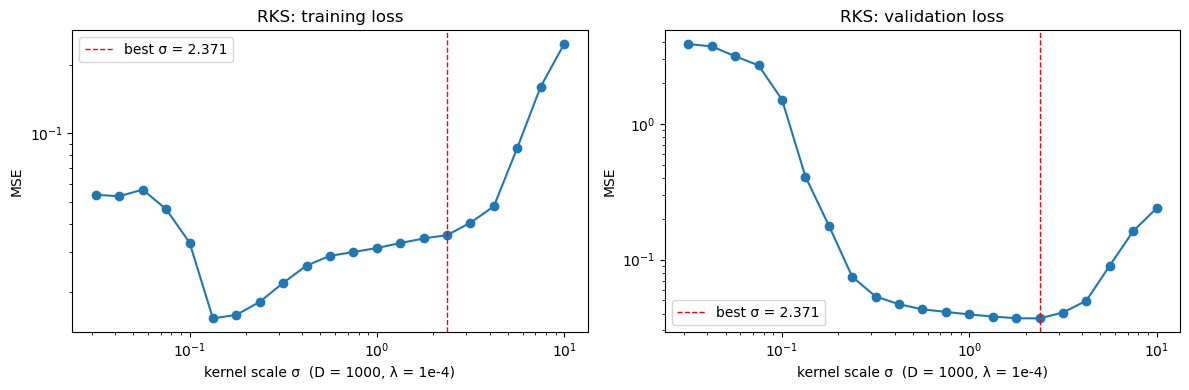

In [26]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, title in [(ax[0], "train MSE", "RKS: training loss"), (ax[1], "val MSE", "RKS: validation loss")]:
    a.plot(rks_sweep["sigma"], rks_sweep[col], "o-")
    a.axvline(best_sigma, color="r", ls="--", lw=1, label=f"best σ = {best_sigma:.3f}")
    a.set_xscale("log"); a.set_yscale("log")
    a.set_xlabel("kernel scale σ  (D = 1000, λ = 1e-4)"); a.set_ylabel("MSE"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

- **Small σ (≤ 0.2):** the random frequencies $w_j \sim \mathcal{N}(0, I/\sigma^2)$ are very large, so the features oscillate much faster than the data. The ridge fit interpolates noise (train MSE ≈ 0.02–0.05) but generalizes terribly (val MSE up to 3.9, worse than predicting the mean). This is **overfitting / high variance**. It is also very unstable across random seeds (val sd up to 0.86).
- **Large σ (≥ 4):** the features are nearly linear/constant over $[-3, 3]^2$ and cannot represent the curvature, so both train and val MSE rise together (0.25 at σ = 10). This is **underfitting / high bias**.
- **Middle (σ ≈ 1–2.4):** train and val MSE are both ≈ 0.035–0.04 and nearly equal, which suggests we have reached the noise level of the data. **Best σ = 2.37 (val MSE 0.0368 averaged over 5 feature draws)**, with D = 1000 and λ = 1e-4.

The training loss decreases with smaller σ (more flexible features) until σ ≈ 0.13. The validation loss is U-shaped, the classic bias–variance trade-off controlled by the kernel bandwidth.

Q3 (c)

**Setup.** One hidden layer with ReLU, trained with Adam (lr = 3e-3) on the MSE with mini-batches of 64 for a fixed 1000 epochs (≈ 10k steps; every configuration gets the same training budget so the sweep only changes one thing). I sweep the **hidden-layer width** over 1 to 512 units.

In [27]:
class MLP(nn.Module):
    """1-hidden-layer MLP for regression."""
    def __init__(self, d_in: int, d_hidden: int = 128, d_out: int = 1, lr: float = 3e-3, batch_size: int = 64,
                 epochs: int = 1000, activation: str = "relu", device: str = "cpu", seed: int = 0):
        super().__init__()
        self.device, self.lr, self.batch_size, self.epochs, self.seed = device, lr, batch_size, epochs, seed
        torch.manual_seed(seed)
        act = {"relu": nn.ReLU(), "tanh": nn.Tanh()}[activation]
        self.net = nn.Sequential(nn.Linear(d_in, d_hidden), act, nn.Linear(d_hidden, d_out)).to(device)

    def fit(self, X: np.ndarray, y: np.ndarray):
        X = torch.from_numpy(X).float().to(self.device)
        y = torch.from_numpy(y).float().view(-1, 1).to(self.device)
        optimizer = torch.optim.Adam(self.net.parameters(), lr=self.lr)
        loss_fn = nn.MSELoss()
        g = torch.Generator().manual_seed(self.seed)
        self.net.train()
        for epoch in range(self.epochs):
            perm = torch.randperm(len(X), generator=g)
            for i in range(0, len(X), self.batch_size):
                idx = perm[i:i + self.batch_size]
                loss = loss_fn(self.net(X[idx]), y[idx])
                optimizer.zero_grad()
                loss.backward()
                optimizer.step()
        self.net.eval()
        return self

    def forward(self, X: torch.Tensor) -> torch.Tensor:
        return self.net(X)

    def predict(self, X: np.ndarray) -> np.ndarray:
        with torch.no_grad():
            X = torch.from_numpy(X).float().to(self.device)
            return self.forward(X).detach().cpu().numpy().ravel()

def mlp_sweep(sweep_values, X_train, y_train, X_val, y_val, **kwargs):
    rows, best = [], (None, float("inf"), None)
    for h in sweep_values:
        t0 = time.time()
        m = MLP(X_train.shape[1], d_hidden=h, **kwargs).fit(X_train, y_train)
        tr, va = mse(y_train, m.predict(X_train)), mse(y_val, m.predict(X_val))
        rows.append({"d_hidden": h, "train MSE": tr, "val MSE": va})
        print(f"d_hidden={h:4d}: train {tr:.4f}  val {va:.4f}  ({time.time() - t0:.1f}s)", flush=True)
        if va < best[1]:
            best = (m, va, h)
    return pd.DataFrame(rows), best

widths = [1, 2, 4, 8, 16, 32, 64, 128, 256, 512]
mlp_res, (best_mlp, best_mlp_val, best_width) = mlp_sweep(widths, X3_tr, y3_tr, X3_va, y3_va)
print(f"best d_hidden = {best_width} (val MSE {best_mlp_val:.4f})")
mlp_res.round(4)

d_hidden=   1: train 2.4634  val 2.3968  (2.4s)
d_hidden=   2: train 0.2901  val 0.2914  (2.4s)
d_hidden=   4: train 0.2929  val 0.2967  (2.4s)
d_hidden=   8: train 0.0455  val 0.0466  (2.5s)
d_hidden=  16: train 0.0338  val 0.0449  (2.4s)
d_hidden=  32: train 0.0304  val 0.0408  (2.5s)
d_hidden=  64: train 0.0304  val 0.0405  (2.6s)
d_hidden= 128: train 0.0286  val 0.0402  (2.7s)
d_hidden= 256: train 0.0289  val 0.0415  (2.9s)
d_hidden= 512: train 0.0290  val 0.0426  (3.7s)
best d_hidden = 128 (val MSE 0.0402)


,d_hidden,train MSE,val MSE
0,1,2.4634,2.3968
1,2,0.2901,0.2914
2,4,0.2929,0.2967
3,8,0.0455,0.0466
4,16,0.0338,0.0449
5,32,0.0304,0.0408
6,64,0.0304,0.0405
7,128,0.0286,0.0402
8,256,0.0289,0.0415
9,512,0.0290,0.0426


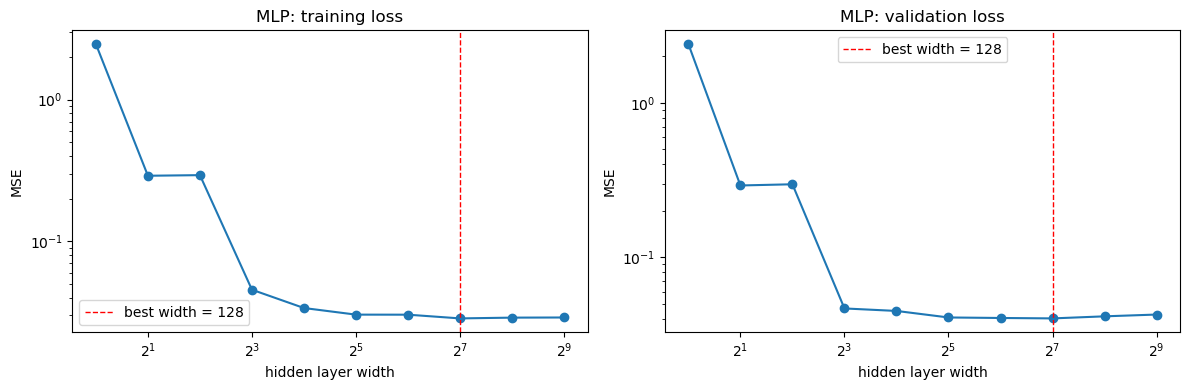

In [28]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for a, col, title in [(ax[0], "train MSE", "MLP: training loss"), (ax[1], "val MSE", "MLP: validation loss")]:
    a.plot(mlp_res["d_hidden"], mlp_res[col], "o-")
    a.axvline(best_width, color="r", ls="--", lw=1, label=f"best width = {best_width}")
    a.set_xscale("log", base=2); a.set_yscale("log")
    a.set_xlabel("hidden layer width"); a.set_ylabel("MSE"); a.set_title(title); a.legend()
plt.tight_layout(); plt.show()

- **Width 1–4:** too few units to represent the surface (width 1 is essentially the mean, MSE ≈ 2.4; widths 2–4 give MSE ≈ 0.29). This is underfitting: train and val losses are equal and high.
- **Width 8:** most of the structure is captured (val 0.047).
- **Width 32–128:** the validation loss plateaus around 0.040, close to the noise level found by RKS. **Best width = 128 (val MSE 0.0402)**, though 32–128 are practically tied.
- **Width 256–512:** training MSE stays at ≈ 0.029 but validation rises slightly (0.0415, 0.0426), a mild sign of overfitting with this fixed budget of 1000 epochs. Note that train MSE (0.029) is below the plateau of val MSE (0.040), so wider networks start fitting some noise.

Compared with RKS, the MLP's validation curve is much flatter on the "too flexible" side. Over-parameterizing the MLP costs little, while choosing σ too small for RKS is catastrophic.

Q3 (d)

In [29]:
# refit both models with the selected hyper-parameters (other settings at their defaults)
rks_final = RandomKitchenSinks(D=1000, sigma=best_sigma, ridge_lambda=1e-4, seed=0).fit(X3_tr, y3_tr)
mlp_final = MLP(2, d_hidden=best_width, seed=0).fit(X3_tr, y3_tr)

q3_results = pd.DataFrame([
    {"model": "predict train mean", "train MSE": mse(y3_tr, np.full_like(y3_tr, y3_tr.mean())),
     "val MSE": mse(y3_va, np.full_like(y3_va, y3_tr.mean()))},
    {"model": f"RKS (D=1000, σ={best_sigma:.3f}, λ=1e-4)", "train MSE": mse(y3_tr, rks_final.predict(X3_tr)),
     "val MSE": mse(y3_va, rks_final.predict(X3_va))},
    {"model": f"1-hidden-layer MLP (width {best_width})", "train MSE": mse(y3_tr, mlp_final.predict(X3_tr)),
     "val MSE": mse(y3_va, mlp_final.predict(X3_va))},
])
display(q3_results.round(4))

# predictions on the unlabeled test set, one per row, same order as test.csv
rks_test = rks_final.predict(X3_te)
mlp_test = mlp_final.predict(X3_te)
pd.DataFrame({"y_pred": rks_test}).to_csv("rks_test_predictions.csv", index=False)
pd.DataFrame({"y_pred": mlp_test}).to_csv("mlp_test_predictions.csv", index=False)
print("saved rks_test_predictions.csv", rks_test.shape, "and mlp_test_predictions.csv", mlp_test.shape)
print("correlation between the two models' test predictions:", round(np.corrcoef(rks_test, mlp_test)[0, 1], 4))
print(pd.read_csv("rks_test_predictions.csv").head(3))

,model,train MSE,val MSE
0,predict train mean,2.4633,2.3966
1,"RKS (D=1000, σ=2.371, λ=1e-4)",0.0365,0.0380
2,1-hidden-layer MLP (width 128),0.0286,0.0402


saved rks_test_predictions.csv (200,) and mlp_test_predictions.csv (200,)
correlation between the two models' test predictions: 0.9986
     y_pred
0  4.936680
1  0.949286
2  2.222263


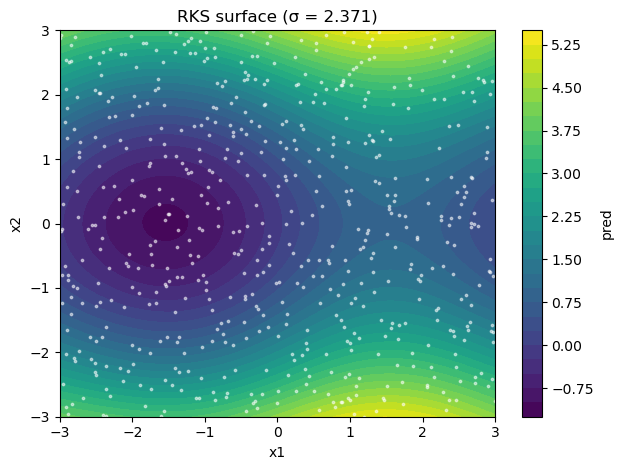

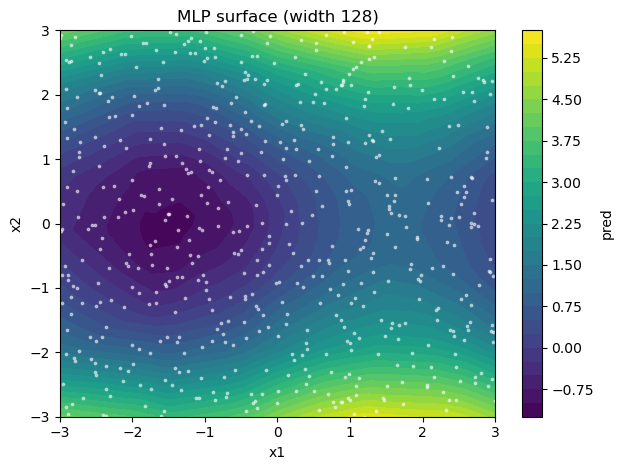

In [30]:
# fitted surfaces with the provided helper (it also saves a .png)
plot_surface_2d(rks_final.predict, (-3, 3), (-3, 3), title=f"RKS surface (σ = {best_sigma:.3f})", filename="rks_surface.png")
plt.scatter(X3_tr[:, 0], X3_tr[:, 1], c="w", s=3, alpha=0.5); plt.show()
plot_surface_2d(mlp_final, (-3, 3), (-3, 3), title=f"MLP surface (width {best_width})", filename="mlp_surface.png")
plt.scatter(X3_tr[:, 0], X3_tr[:, 1], c="w", s=3, alpha=0.5); plt.show()

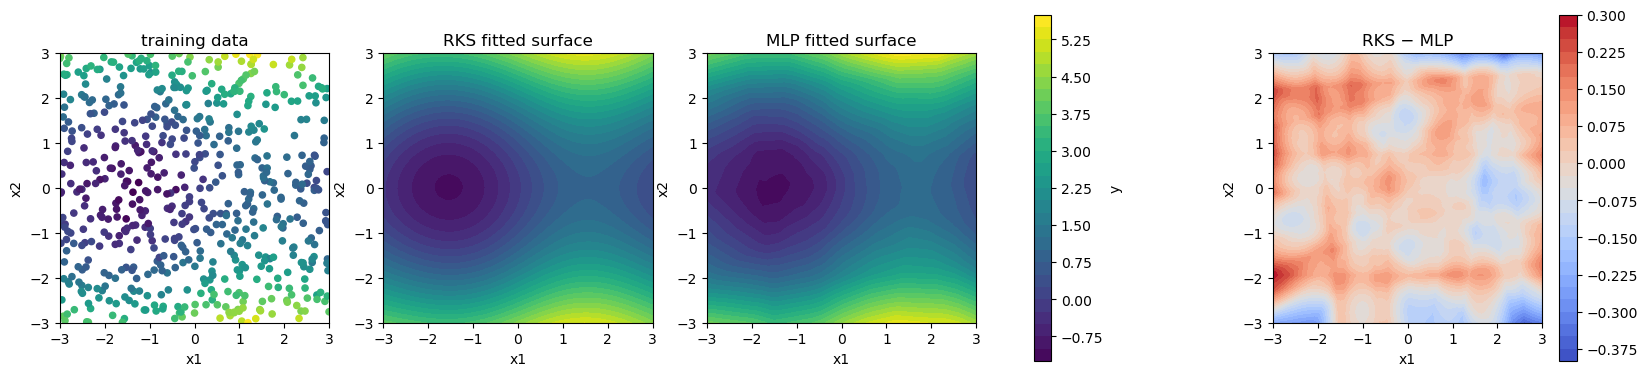

In [31]:
# side by side on a common colour scale, plus the difference between the two fits
g = np.linspace(-3, 3, 200)
G1, G2 = np.meshgrid(g, g)
Xg = np.stack([G1.ravel(), G2.ravel()], 1)
Z_rks = rks_final.predict(Xg).reshape(200, 200)
Z_mlp = mlp_final.predict(Xg).reshape(200, 200)
vmin, vmax = min(y3_tr.min(), Z_rks.min(), Z_mlp.min()), max(y3_tr.max(), Z_rks.max(), Z_mlp.max())

fig, ax = plt.subplots(1, 4, figsize=(20, 4.5))
ax[0].scatter(X3_tr[:, 0], X3_tr[:, 1], c=y3_tr, cmap="viridis", vmin=vmin, vmax=vmax, s=20); ax[0].set_title("training data")
for a, Z, t in [(ax[1], Z_rks, "RKS"), (ax[2], Z_mlp, "MLP")]:
    cf = a.contourf(G1, G2, Z, levels=30, cmap="viridis", vmin=vmin, vmax=vmax); a.set_title(f"{t} fitted surface")
fig.colorbar(cf, ax=ax[:3].tolist(), label="y")
d = ax[3].contourf(G1, G2, Z_rks - Z_mlp, levels=30, cmap="coolwarm"); ax[3].set_title("RKS − MLP")
fig.colorbar(d, ax=ax[3])
for a in ax:
    a.set_xlim(-3, 3); a.set_ylim(-3, 3); a.set_aspect("equal"); a.set_xlabel("x1"); a.set_ylabel("x2")
plt.show()

**Validation MSE of the refitted models:** RKS (D = 1000, σ = 2.37, λ = 1e-4) **0.0380**, MLP (width 128) **0.0402**, predicting the mean 2.40. Both models explain about 98% of the variance. **RKS is slightly better** on validation (and has a slightly higher training error, 0.0365 vs 0.0286, i.e. it fits less noise). The difference is small: the two models' predictions on the test set have correlation 0.9986. Test predictions are saved in `rks_test_predictions.csv` and `mlp_test_predictions.csv` (one column `y_pred`, 200 rows in the order of `test.csv`).

**Why RKS has a slight edge here.** The target is a smooth, low-frequency function in only 2 dimensions with 600 noisy points. RKS with a Gaussian-kernel bandwidth of σ ≈ 2.4 is essentially kernel ridge regression with a smoothness prior that matches this function well. It is fit in closed form, with an explicit L2 penalty, and no optimization noise. The MLP has to *learn* its features (the hidden-unit directions and offsets) by stochastic gradient descent without explicit regularization. With 600 points it fits a bit more noise (lower train, higher val MSE), and its results depend on initialization and training length. The MLP's advantage, adapting its features to the data instead of drawing them at random, matters more in higher dimensions or for functions with localized, non-smooth structure, which this dataset does not have.

**Comparing the surfaces with the data in (a).** Both fitted surfaces reproduce the structure seen in the training data: the basin near (−1.5, 0), the saddle near (1.5, 0), and y rising toward $x_2 = \pm 3$. The **RKS surface is very smooth**, with rounded contours: it is a weighted sum of 500 random sinusoids at low frequencies, which can only make smooth functions. The **MLP surface is piecewise linear**: a ReLU network partitions the plane into polygons and fits a linear function on each, visible as slightly angular contour lines. The difference map (RKS − MLP) is mostly within ±0.15 inside the data region, with a blocky pattern that comes from the MLP's linear pieces. It is largest (about 0.3–0.4) at the edges and corners of $[-3, 3]^2$, where there are few training points and each model extrapolates according to its own inductive bias (smooth sinusoids vs. linear pieces).